# SolarOps Maroc : exploration complète des données (jour 3)

**Objectif** : comprendre les données avant de les transformer (dbt) et de les modéliser, et en tirer des **règles de qualité justifiées**.

**Comment l'utiliser** : menu *Run, Run All Cells*. Chaque section produit des tableaux ou des graphiques, suivis d'une consigne **« À regarder »**. Notez vos observations dans la section finale.

| Section | Question |
|---|---|
| 1 | Les données sont-elles chargées correctement ? |
| 2 | Sont-elles complètes (pas de trou, pas de doublon) ? |
| 3 | À quoi ressemblent les variables (statistiques) ? |
| 4 | Les valeurs sont-elles physiquement plausibles ? |
| 5 | Le rayonnement est-il bien nul la nuit ? Quelle est la durée du jour ? |
| 6 à 8 | Comment le rayonnement varie-t-il (heure, mois, année, ville) ? |
| 9 | Quel est l'effet des nuages ? |
| 10 | Quel est l'indice de clarté (part du ciel dégagé) ? |
| 11 | Y a-t-il des jours « anormalement sombres » sans nuages (piste Chergui) ? |
| 12 à 13 | Température, humidité, vent, corrélations |
| 14 | Comparaison des villes |
| 15 | Quel niveau d'erreur donnent des baselines simples ? |
| 16 | Synthèse : règles de qualité proposées |

**Rappels** : les heures sont en **UTC** (le Maroc est en général à UTC+1). `shortwave_radiation` est une moyenne horaire en W/m². Je pense que la valeur étiquetée *h* correspond à l'heure qui précède *h* (à vérifier dans la documentation d'Open-Meteo).

## 1. Chargement

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Réglages d'affichage ---------------------------------------------------
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

RAD = "shortwave_radiation"  # la variable à prévoir (W/m², moyenne horaire)
VARS = [
    RAD, "temperature_2m", "relative_humidity_2m", "surface_pressure",
    "cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high",
    "wind_speed_10m", "wind_direction_10m", "precipitation",
]

# --- Localiser la racine du projet (le dossier qui contient "data") ---------
# Fonctionne que le notebook soit à la racine ou dans notebooks/
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

files = sorted((ROOT / "data" / "raw").glob("*/*.parquet"))
assert files, f"Aucun fichier Parquet sous {ROOT / 'data' / 'raw'} : lancez d'abord l'ingestion."

df = pd.concat((pd.read_parquet(f) for f in files), ignore_index=True)
df["time"] = pd.to_datetime(df["time"])
df = df.sort_values(["city", "time"]).reset_index(drop=True)

CITIES = sorted(df["city"].unique())
CITY_FOCUS = "Tanger"  # ville utilisée pour les graphiques de détail (modifiable)
if CITY_FOCUS not in CITIES:
    CITY_FOCUS = CITIES[0]

print(f"Racine du projet : {ROOT}")
print(f"{len(files)} fichiers, {df.shape[0]:,} lignes, {df.shape[1]} colonnes")
print("Villes :", CITIES)

Racine du projet : /app
50 fichiers, 438,360 lignes, 13 colonnes
Villes : ['Al Hoceima', 'Dakhla', 'Laayoune', 'Ouarzazate', 'Tanger']


In [2]:
# --- Colonnes de calendrier (utilisées partout dans la suite) ---------------
SEASONS = {
    12: "hiver", 1: "hiver", 2: "hiver",
    3: "printemps", 4: "printemps", 5: "printemps",
    6: "été", 7: "été", 8: "été",
    9: "automne", 10: "automne", 11: "automne",
}
SEASON_ORDER = ["hiver", "printemps", "été", "automne"]

df["date"] = df["time"].dt.normalize()
df["hour"] = df["time"].dt.hour
df["month"] = df["time"].dt.month
df["year"] = df["time"].dt.year
df["season"] = df["month"].map(SEASONS)
df.head()

,city,time,shortwave_radiation,temperature_2m,relative_humidity_2m,surface_pressure,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_speed_10m,wind_direction_10m,precipitation,date,hour,month,year,season
0,Al Hoceima,2015-01-01 00:00:00,0.00,8.90,76,"1,019.80",0,0,0,0,6.60,221,0.00,2015-01-01,0,1,2015,hiver
1,Al Hoceima,2015-01-01 01:00:00,0.00,9.60,78,"1,019.70",0,0,0,0,7.20,207,0.00,2015-01-01,1,1,2015,hiver
2,Al Hoceima,2015-01-01 02:00:00,0.00,10.20,78,"1,019.60",0,0,0,0,7.30,200,0.00,2015-01-01,2,1,2015,hiver
3,Al Hoceima,2015-01-01 03:00:00,0.00,10.10,79,"1,019.70",0,0,0,0,7.30,191,0.00,2015-01-01,3,1,2015,hiver
4,Al Hoceima,2015-01-01 04:00:00,0.00,9.90,82,"1,019.70",0,0,0,0,6.90,189,0.00,2015-01-01,4,1,2015,hiver


**À regarder** : on attend **50 fichiers** (5 villes × 10 ans) et environ **438 360 lignes**, soit 87 672 par ville.

## 2. Intégrité : complétude, doublons, trous

La granularité attendue est **une ligne par ville et par heure**. La combinaison (ville, heure) doit donc être **unique**, et la série doit être **continue**, soit 24 lignes par jour.

In [3]:
full_range = pd.date_range(df["time"].min(), df["time"].max(), freq="h")
rows = []
for city, g in df.groupby("city"):
    rows.append({
        "ville": city,
        "lignes": len(g),
        "heures uniques": g["time"].nunique(),
        "doublons": len(g) - g["time"].nunique(),
        "heures manquantes": len(full_range.difference(pd.DatetimeIndex(g["time"]))),
        "début": g["time"].min(),
        "fin": g["time"].max(),
    })
integrity = pd.DataFrame(rows).set_index("ville")
integrity

,lignes,heures uniques,doublons,heures manquantes,début,fin
ville,,,,,,
Al Hoceima,87672,87672,0,0,2015-01-01,2024-12-31 23:00:00
Dakhla,87672,87672,0,0,2015-01-01,2024-12-31 23:00:00
Laayoune,87672,87672,0,0,2015-01-01,2024-12-31 23:00:00
Ouarzazate,87672,87672,0,0,2015-01-01,2024-12-31 23:00:00
Tanger,87672,87672,0,0,2015-01-01,2024-12-31 23:00:00


In [4]:
per_day = df.groupby(["city", "date"]).size().value_counts()
print("Nombre de lignes par jour et par ville (attendu : 24 partout, 'jours' = nombre de cas) :")
print(per_day.to_string())

missing = df[VARS].isna().sum()
print()
print(missing[missing > 0] if (missing > 0).any() else "Aucune valeur manquante dans les variables.")

Nombre de lignes par jour et par ville (attendu : 24 partout, 'jours' = nombre de cas) :
24    18265

Aucune valeur manquante dans les variables.


**À regarder** : `doublons` et `heures manquantes` doivent valoir **0** pour chaque ville, et `24` doit être la seule valeur de la liste. Sinon, notez la ville et la période concernées : c'est la matière d'un test dbt.

## 3. Statistiques descriptives

In [5]:
df[VARS].describe().T

,count,mean,std,min,25%,50%,75%,max
shortwave_radiation,"438,360.00",234.65,312.47,0.00,0.00,12.00,473.00,"1,095.00"
temperature_2m,"438,360.00",19.50,6.29,-5.10,15.40,19.50,23.40,46.80
relative_humidity_2m,"438,360.00",62.20,24.59,2.00,45.00,66.00,83.00,100.00
surface_pressure,"438,360.00",987.24,47.92,872.60,"1,003.70","1,009.00","1,013.70","1,033.00"
cloud_cover,"438,360.00",32.48,38.34,0.00,0.00,11.00,68.00,100.00
cloud_cover_low,"438,360.00",10.95,24.67,0.00,0.00,0.00,6.00,100.00
cloud_cover_mid,"438,360.00",8.63,21.23,0.00,0.00,0.00,2.00,100.00
cloud_cover_high,"438,360.00",20.69,35.06,0.00,0.00,0.00,28.00,100.00
wind_speed_10m,"438,360.00",15.81,9.59,0.00,7.40,14.60,23.10,59.40
wind_direction_10m,"438,360.00",148.04,117.74,0.00,35.00,108.00,262.00,360.00


In [6]:
print("Moyenne de chaque variable par ville :")
df.groupby("city")[VARS].mean().T

Moyenne de chaque variable par ville :


city,Al Hoceima,Dakhla,Laayoune,Ouarzazate,Tanger
shortwave_radiation,212.97,258.18,245.18,243.94,212.96
temperature_2m,18.46,20.94,20.79,19.15,18.16
relative_humidity_2m,70.59,66.42,63.29,34.19,76.52
surface_pressure,"1,008.67","1,014.93","1,008.57",891.94,"1,012.08"
cloud_cover,37.05,24.55,32.83,27.91,40.04
cloud_cover_low,12.84,4.12,16.86,2.51,18.45
cloud_cover_mid,10.64,4.94,4.51,12.30,10.77
cloud_cover_high,24.75,18.57,15.70,19.90,24.51
wind_speed_10m,10.01,23.64,20.84,9.52,15.01
wind_direction_10m,183.58,76.96,94.66,215.54,169.45


**À regarder** : l'ordre de grandeur de chaque variable, et les différences entre villes (par exemple pression plus basse à Ouarzazate, qui est en altitude, vent plus fort sur la côte).

## 4. Plausibilité physique

On compare chaque variable à une **plage physiquement possible**. Ces plages deviendront des **tests dbt** (jour 4). Si une valeur sort de la plage, c'est soit une anomalie des données, soit une plage mal choisie : dans les deux cas, il faut le justifier.

In [7]:
PHYSICAL_RANGES = {
    RAD: (0, 1400),
    "temperature_2m": (-30, 60),
    "relative_humidity_2m": (0, 100),
    "surface_pressure": (800, 1100),   # hPa
    "cloud_cover": (0, 100),
    "cloud_cover_low": (0, 100),
    "cloud_cover_mid": (0, 100),
    "cloud_cover_high": (0, 100),
    "wind_speed_10m": (0, 200),        # km/h
    "wind_direction_10m": (0, 360),
    "precipitation": (0, 100),         # mm par heure
}
checks = []
for var, (low, high) in PHYSICAL_RANGES.items():
    out = ((df[var] < low) | (df[var] > high)).sum()
    checks.append({
        "variable": var,
        "min observé": df[var].min(),
        "max observé": df[var].max(),
        "plage autorisée": f"{low} à {high}",
        "lignes hors plage": int(out),
    })
range_checks = pd.DataFrame(checks).set_index("variable")
range_checks

,min observé,max observé,plage autorisée,lignes hors plage
variable,,,,
shortwave_radiation,0.00,"1,095.00",0 à 1400,0
temperature_2m,-5.10,46.80,-30 à 60,0
relative_humidity_2m,2.00,100.00,0 à 100,0
surface_pressure,872.60,"1,033.00",800 à 1100,0
cloud_cover,0.00,100.00,0 à 100,0
cloud_cover_low,0.00,100.00,0 à 100,0
cloud_cover_mid,0.00,100.00,0 à 100,0
cloud_cover_high,0.00,100.00,0 à 100,0
wind_speed_10m,0.00,59.40,0 à 200,0


**À regarder** : `lignes hors plage` doit valoir 0. Le maximum du rayonnement est-il sous 1 400 W/m² (limite physique raisonnable) ? Si vous voulez resserrer un seuil, appuyez-vous sur le maximum observé.

## 5. Rayonnement la nuit et durée du jour

Le rayonnement doit être **nul** quand le soleil est couché. C'est le test « pas de production la nuit ».

In [8]:
night_hours = [0, 1, 2, 3]
night_max = df[df["hour"].isin(night_hours)].groupby("city")[RAD].max()
print("Rayonnement maximal observé entre 0h et 3h UTC, par ville :")
print(night_max.to_string())

Rayonnement maximal observé entre 0h et 3h UTC, par ville :
city
Al Hoceima   0.00
Dakhla       0.00
Laayoune     0.00
Ouarzazate   0.00
Tanger       0.00


In [9]:
# Première et dernière heure où le rayonnement moyen dépasse 5 W/m², par ville et saison
mean_hs = df.groupby(["city", "season", "hour"])[RAD].mean().reset_index()
sun = (
    mean_hs[mean_hs[RAD] > 5]
    .groupby(["city", "season"])["hour"]
    .agg(["min", "max"])
    .rename(columns={"min": "première heure", "max": "dernière heure"})
)
sun["durée (h)"] = sun["dernière heure"] - sun["première heure"] + 1
sun.reindex(SEASON_ORDER, level="season")

première heure  dernière heure  durée (h)
city       season                                              
Al Hoceima hiver                   8              18         11
           printemps               6              19         14
           été                     6              19         14
           automne                 7              18         12
Dakhla     hiver                   9              19         11
           printemps               7              20         14
           été                     7              20         14
           automne                 8              19         12
Laayoune   hiver                   8              19         12
           printemps               7              20         14
           été                     7              20         14
           automne                 8              19         12
Ouarzazate hiver                   8              18         11
           printemps               7              19         13
           été                     6              20         15
           automne                 7              18         12
Tanger     hiver                   8              18         11
           printemps               6              19         14
           été                     6              20         15
           automne                 7              18         12

**À regarder** : le maximum la nuit doit être **0 ou presque**. Les jours sont plus longs en été qu'en hiver, et plus longs au nord (Tanger) qu'au sud (Dakhla) en été, l'inverse en hiver.

## 6. Profil moyen sur 24 heures

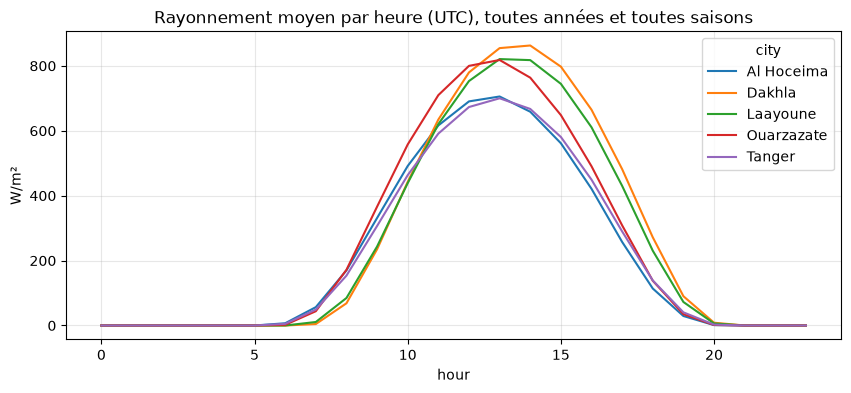

In [10]:
profile = df.groupby(["hour", "city"])[RAD].mean().unstack("city")
ax = profile.plot(title="Rayonnement moyen par heure (UTC), toutes années et toutes saisons")
ax.set_ylabel("W/m²")
plt.show()

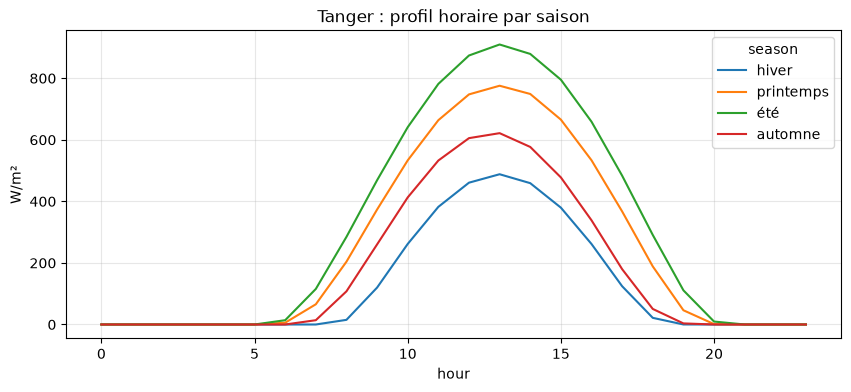

In [11]:
focus = df[df["city"] == CITY_FOCUS]
by_season = focus.groupby(["hour", "season"])[RAD].mean().unstack("season")[SEASON_ORDER]
ax = by_season.plot(title=f"{CITY_FOCUS} : profil horaire par saison")
ax.set_ylabel("W/m²")
plt.show()

**À regarder** : une cloche centrée vers 12 à 13 h UTC. La cloche d'été est plus haute et plus large que celle d'hiver. Les courbes des villes à l'ouest (Dakhla) sont-elles décalées vers la droite par rapport à celles de l'est (Al Hoceima) ?

## 7. Saisonnalité

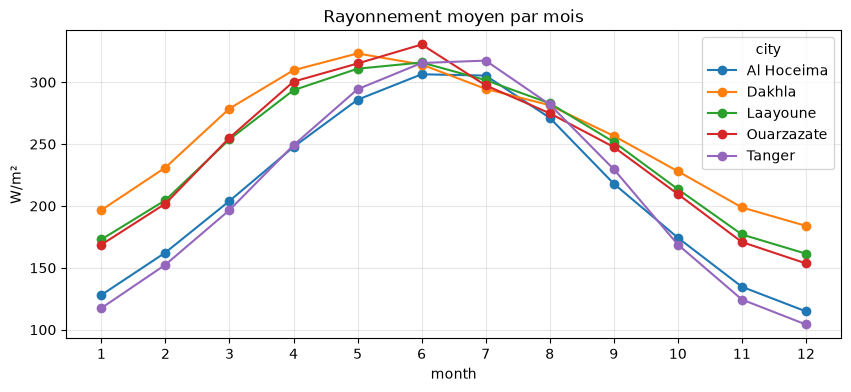

In [12]:
monthly = df.groupby(["month", "city"])[RAD].mean().unstack("city")
ax = monthly.plot(marker="o", title="Rayonnement moyen par mois")
ax.set_ylabel("W/m²")
ax.set_xticks(range(1, 13))
plt.show()

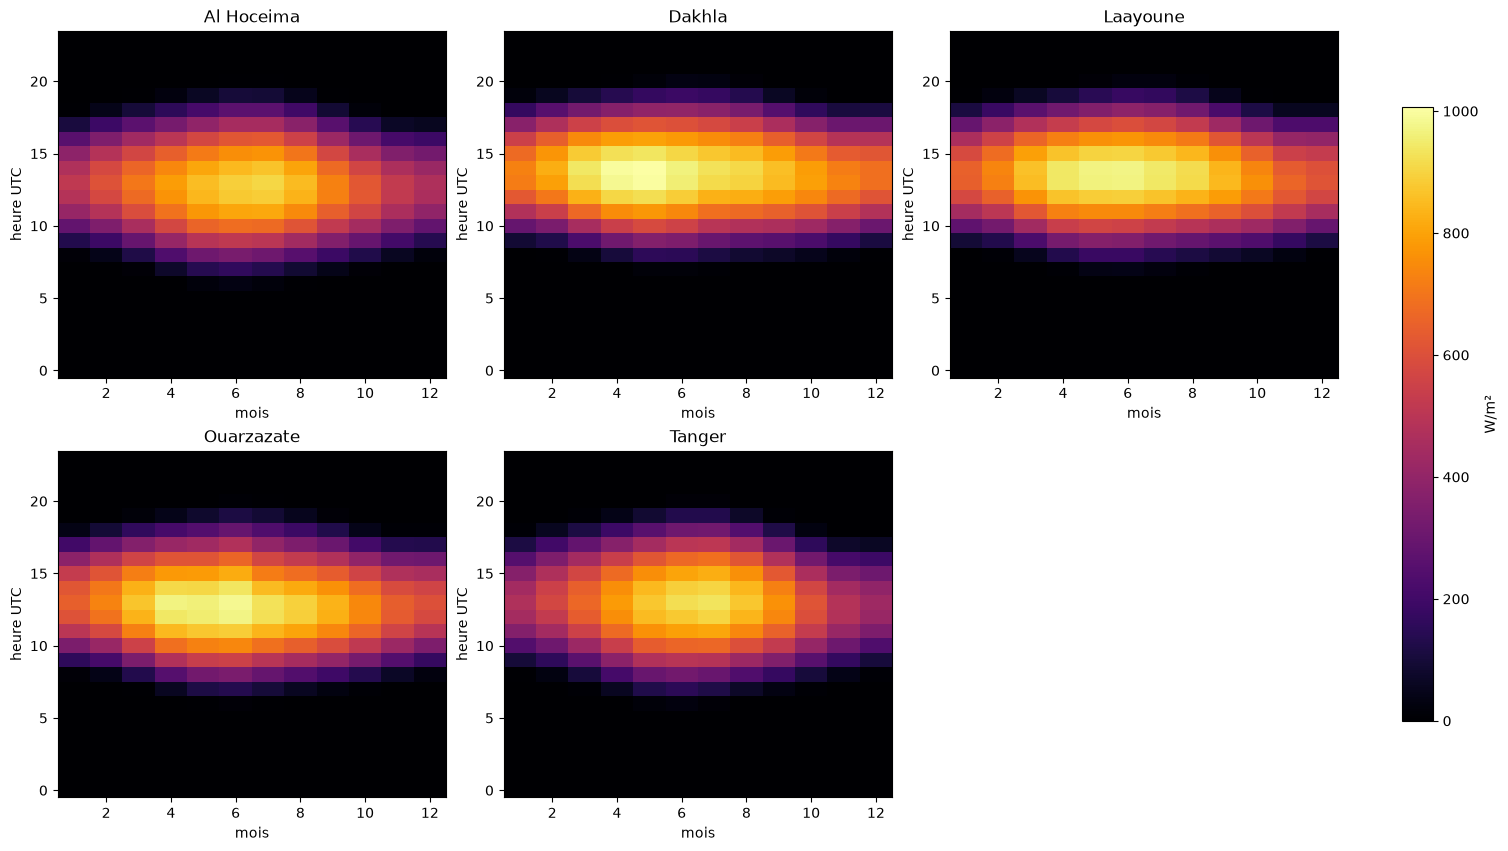

In [13]:
# Carte chaleur heure x mois pour chaque ville : la 'signature solaire' du site
pivots = {
    c: df[df["city"] == c].pivot_table(index="hour", columns="month", values=RAD, aggfunc="mean")
    for c in CITIES
}
vmax = max(p.values.max() for p in pivots.values())
ncols = 3
nrows = int(np.ceil(len(CITIES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.2 * nrows), squeeze=False, layout="constrained")
for ax in axes.ravel():
    ax.axis("off")
for ax, (city, p) in zip(axes.ravel(), pivots.items()):
    ax.axis("on")
    im = ax.imshow(p.values, origin="lower", aspect="auto", vmin=0, vmax=vmax, cmap="inferno",
                   extent=[0.5, 12.5, -0.5, 23.5])
    ax.set_title(city)
    ax.set_xlabel("mois")
    ax.set_ylabel("heure UTC")
    ax.grid(False)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="W/m²")
plt.show()

**À regarder** : un maximum en été et un minimum en hiver. L'écart été-hiver est-il plus marqué au nord qu'au sud ? Quelle ville reçoit le plus de rayonnement sur l'année ?

## 8. Variabilité d'une année à l'autre

On passe à l'échelle **journalière** : énergie du jour en kWh/m² (somme des 24 valeurs horaires, divisée par 1 000).

In [14]:
daily = (
    df.groupby(["city", "date"])
    .agg(
        energy_wh=(RAD, "sum"),
        cloud=("cloud_cover", "mean"),
        temp=("temperature_2m", "mean"),
        wind=("wind_speed_10m", "mean"),
        rain=("precipitation", "sum"),
    )
    .reset_index()
)
daily["energy_kwh"] = daily["energy_wh"] / 1000
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month

print("Énergie journalière moyenne (kWh/m²/jour) par année et par ville :")
daily.pivot_table(index="year", columns="city", values="energy_kwh", aggfunc="mean")

Énergie journalière moyenne (kWh/m²/jour) par année et par ville :


city,Al Hoceima,Dakhla,Laayoune,Ouarzazate,Tanger
year,,,,,
2015,5.32,6.27,5.99,5.95,5.15
2016,5.35,6.21,5.87,5.94,5.10
2017,5.15,6.22,5.93,5.94,5.32
2018,4.91,6.18,5.74,5.74,4.94
2019,5.12,6.26,5.88,5.86,5.17
2020,5.00,6.15,5.87,5.80,5.07
2021,4.94,6.16,5.91,5.81,5.04
2022,5.04,6.15,5.87,5.74,5.09
2023,5.20,6.18,5.92,5.86,5.18


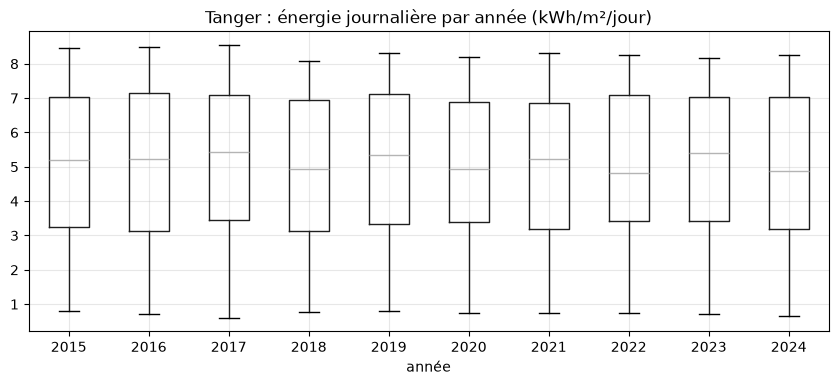

In [15]:
d = daily[daily["city"] == CITY_FOCUS]
d.boxplot(column="energy_kwh", by="year", figsize=(10, 4))
plt.suptitle("")
plt.title(f"{CITY_FOCUS} : énergie journalière par année (kWh/m²/jour)")
plt.xlabel("année")
plt.show()

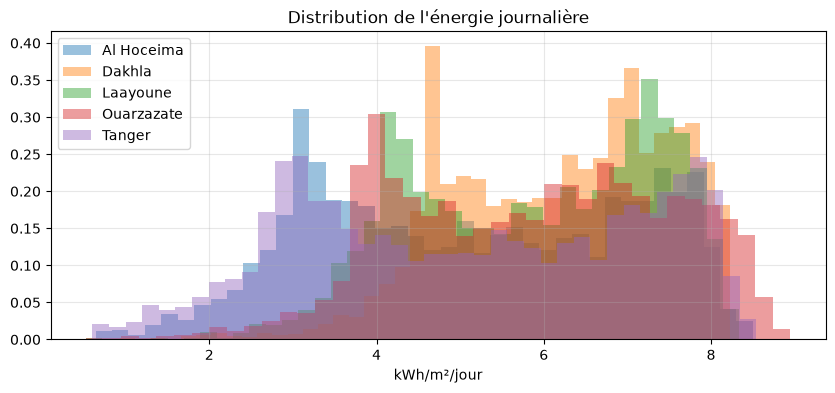

In [16]:
for city, g in daily.groupby("city"):
    plt.hist(g["energy_kwh"], bins=40, alpha=0.45, density=True, label=city)
plt.title("Distribution de l'énergie journalière")
plt.xlabel("kWh/m²/jour")
plt.legend()
plt.show()

**À regarder** : les moyennes annuelles sont-elles proches (stabilité) ou une année ressort-elle ? Les distributions sont-elles **asymétriques** (beaucoup de jours très ensoleillés et quelques jours sombres) ? Cela guide le choix des métriques.

## 9. Effet des nuages

On regarde le rayonnement **à midi** (11 h à 13 h UTC), pour éviter l'effet de l'heure, selon la couverture nuageuse totale, puis par couche (basse, moyenne, haute).

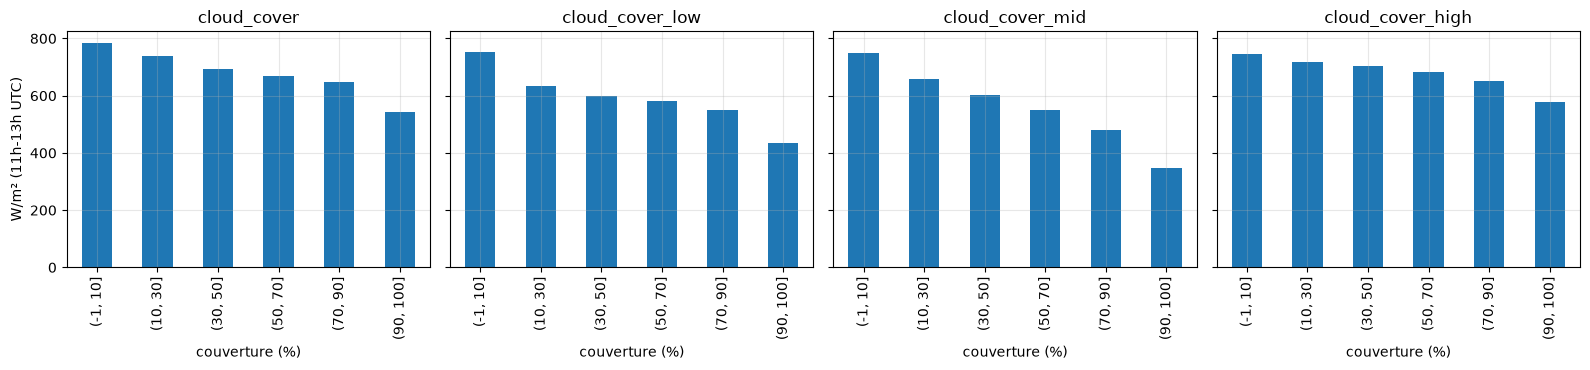

In [17]:
noon = df[df["hour"].between(11, 13)]
bins = [-1, 10, 30, 50, 70, 90, 100]
cloud_cols = ["cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, col in zip(axes, cloud_cols):
    groups = pd.cut(noon[col], bins)
    noon.groupby(groups, observed=True)[RAD].mean().plot(kind="bar", ax=ax, title=col)
    ax.set_xlabel("couverture (%)")
axes[0].set_ylabel("W/m² (11h-13h UTC)")
plt.tight_layout()
plt.show()

**À regarder** : plus il y a de nuages, moins il y a de rayonnement. Quelle couche pèse le plus ? La baisse est-elle régulière ou en paliers ? Cela justifie de garder les trois couches comme variables séparées.

## 10. Indice de clarté empirique

**Idée** : pour chaque ville, mois et heure, on prend le 95ᵉ percentile du rayonnement observé comme **enveloppe de ciel dégagé** (un proxy, pas le vrai ciel clair). L'**indice de clarté** est le rapport entre le rayonnement observé et cette enveloppe : proche de 1 = ciel dégagé, proche de 0 = ciel très couvert.

C'est une approximation. Le calcul physique exact se fera plus tard avec une bibliothèque dédiée (pvlib).

In [18]:
clear = df.groupby(["city", "month", "hour"])[RAD].quantile(0.95).rename("clear_sky_p95")
df = df.join(clear, on=["city", "month", "hour"])
valid = df["clear_sky_p95"] > 20  # on ignore la nuit et les heures de très faible soleil
df["clearness"] = np.where(valid, df[RAD] / df["clear_sky_p95"], np.nan)

clearness_day = df.groupby(["city", "date"])["clearness"].mean().rename("clearness_day").reset_index()
daily = daily.drop(columns=["clearness_day"], errors="ignore").merge(clearness_day, on=["city", "date"])
daily["sky"] = pd.cut(
    daily["clearness_day"].clip(upper=1.5),
    bins=[-0.01, 0.5, 0.85, 2.0],
    labels=["couvert", "variable", "dégagé"],
)
share = daily.groupby("city")["sky"].value_counts(normalize=True).unstack() * 100
print("Part des jours par type de ciel (%) :")
share

Part des jours par type de ciel (%) :


sky,couvert,variable,dégagé
city,,,
Al Hoceima,6.32,51.27,42.40
Dakhla,0.90,31.56,67.53
Laayoune,0.90,43.77,55.32
Ouarzazate,2.27,52.04,45.69
Tanger,7.99,49.49,42.51


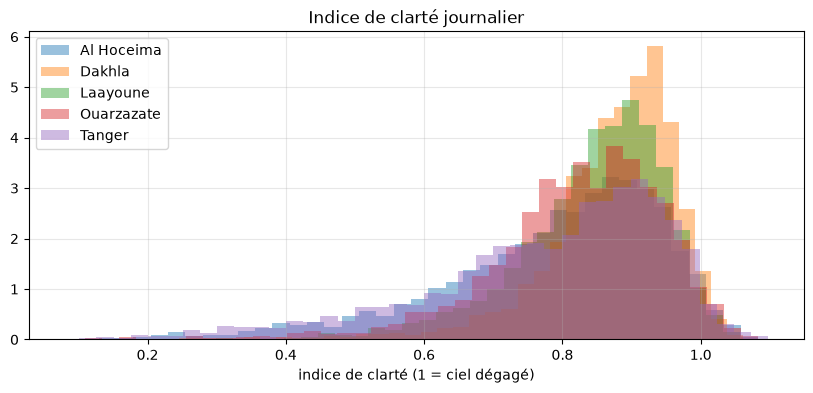

In [19]:
for city, g in daily.groupby("city"):
    plt.hist(g["clearness_day"].clip(upper=1.2), bins=40, alpha=0.45, density=True, label=city)
plt.title("Indice de clarté journalier")
plt.xlabel("indice de clarté (1 = ciel dégagé)")
plt.legend()
plt.show()

**À regarder** : quelle ville a le plus de jours dégagés ? Les distributions ont-elles un pic proche de 1 (ciel dégagé fréquent, surtout au sud) ? Cet indice est aussi une **variable candidate** pour le modèle.

## 11. Jours sombres sans nuages : piste « Chergui » et poussière

**Hypothèse** : un jour où le rayonnement est faible **alors que la couverture nuageuse est faible** peut être dû à autre chose que des nuages : poussière, brume, sable en suspension (par exemple lors d'un épisode de Chergui), ou erreur de la réanalyse. Ce n'est qu'une **piste à vérifier** (par exemple avec des données de qualité de l'air), pas une preuve.

In [20]:
cand = daily[(daily["clearness_day"] < 0.6) & (daily["cloud"] < 20)].copy()
print(f"{len(cand)} jours candidats (indice de clarté < 0,6 et nuages moyens < 20 %)")
if cand.empty:
    print("Aucun jour candidat avec ces seuils.")
else:
    print()
    print("Nombre de jours candidats par ville et par mois :")
    print(cand.groupby(["city", "month"]).size().unstack(fill_value=0).to_string())
    print()
    print("Les 15 jours les plus sombres parmi les candidats :")
    display(cand.sort_values("clearness_day").head(15)[["city", "date", "clearness_day", "cloud", "energy_kwh", "wind"]])

0 jours candidats (indice de clarté < 0,6 et nuages moyens < 20 %)
Aucun jour candidat avec ces seuils.


**À regarder** : ces jours sont-ils plus fréquents dans le sud (Ouarzazate, Laâyoune, Dakhla) ? Plutôt au printemps et en été ? Cela justifierait une variable « poussière » à tester en semaine 4.

## 12. Température, humidité, vent

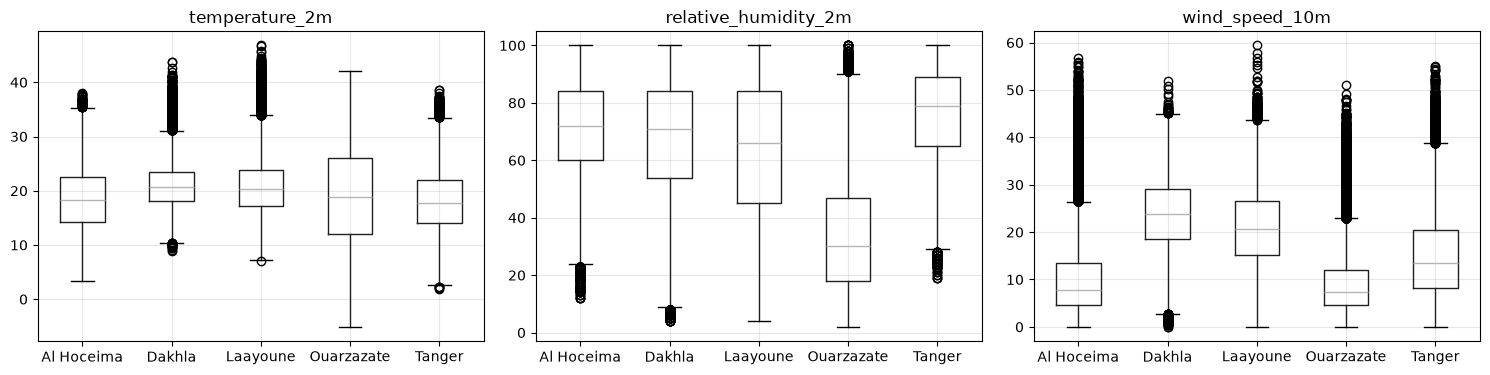

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["temperature_2m", "relative_humidity_2m", "wind_speed_10m"]):
    df.boxplot(column=col, by="city", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

**À regarder** : Ouarzazate (intérieur) a-t-elle des températures plus extrêmes et une humidité plus faible que Tanger (côte) ? Le vent est-il plus fort sur la côte atlantique ?

## 13. Corrélations

Une corrélation globale mélange le jour et la nuit : la nuit, le rayonnement est nul quelle que soit la météo, ce qui **masque** les relations. On compare donc toutes les heures et les **heures de jour** (9 h à 15 h UTC).

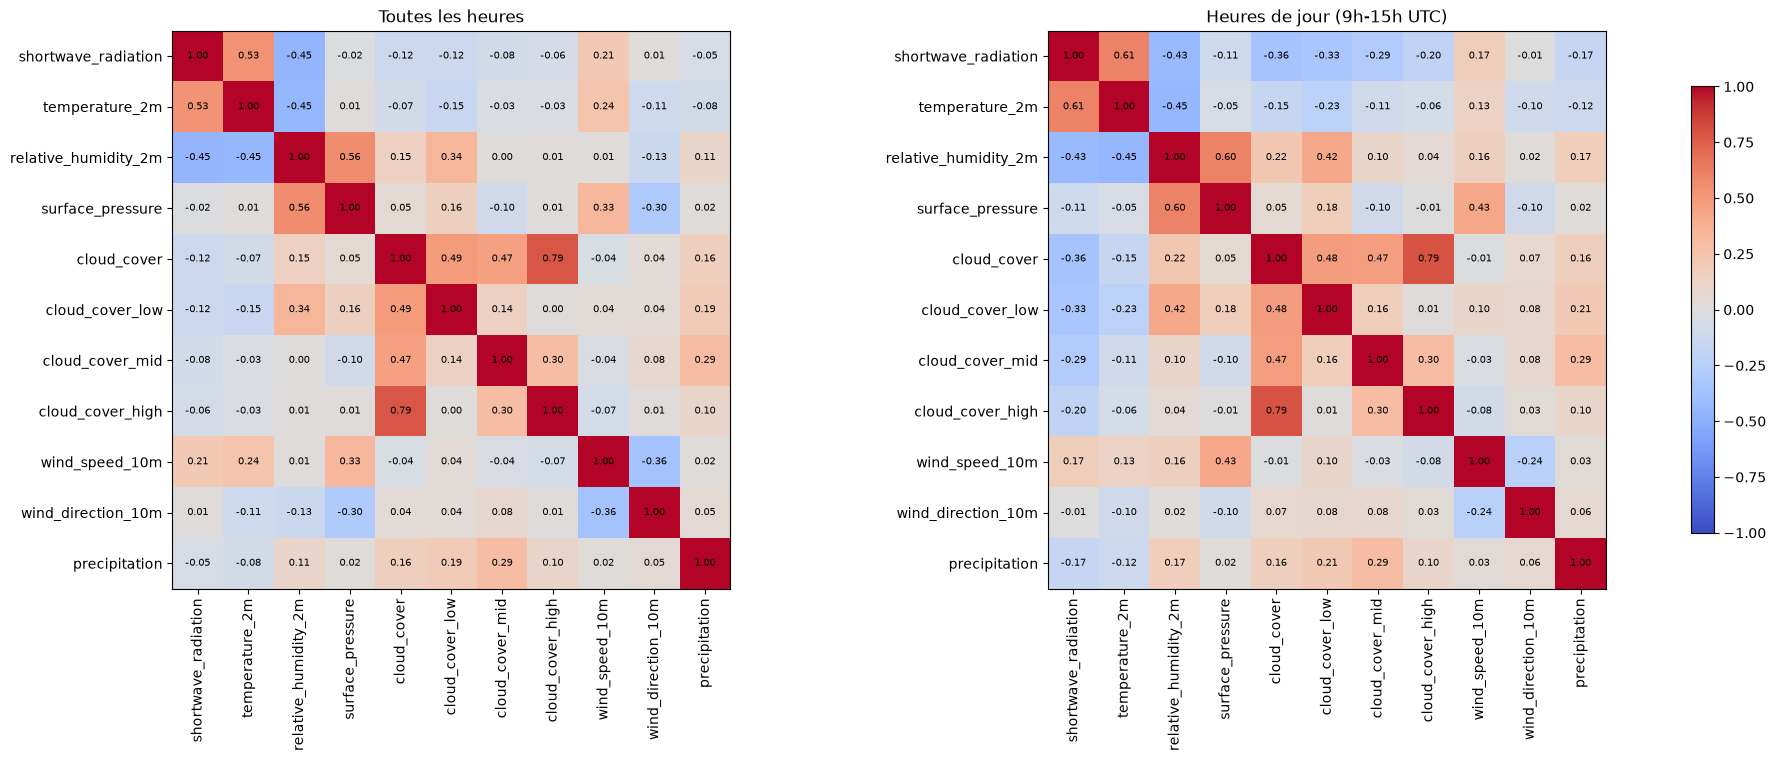

In [22]:
day = df[df["hour"].between(9, 15)]
fig, axes = plt.subplots(1, 2, figsize=(19, 7.5), layout="constrained")
for ax, data, title in zip(axes, [df, day], ["Toutes les heures", "Heures de jour (9h-15h UTC)"]):
    corr = data[VARS].corr()
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(VARS)))
    ax.set_xticklabels(VARS, rotation=90)
    ax.set_yticks(range(len(VARS)))
    ax.set_yticklabels(VARS)
    ax.set_title(title)
    ax.grid(False)
    for i in range(len(VARS)):
        for j in range(len(VARS)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=axes.tolist(), shrink=0.8)
plt.show()

In [23]:
print("Corrélation avec le rayonnement, heures de jour (9h-15h UTC) :")
day.corr(numeric_only=True)[VARS][RAD].drop(RAD).sort_values().round(2)

Corrélation avec le rayonnement, heures de jour (9h-15h UTC) :


relative_humidity_2m   -0.43
cloud_cover            -0.36
cloud_cover_low        -0.33
cloud_cover_mid        -0.29
cloud_cover_high       -0.20
precipitation          -0.17
surface_pressure       -0.11
month                  -0.09
year                   -0.01
wind_direction_10m     -0.01
wind_speed_10m          0.17
hour                    0.53
temperature_2m          0.61
clearness               0.62
clear_sky_p95           0.90
Name: shortwave_radiation, dtype: float64

**À regarder** : quelles variables sont les plus liées au rayonnement le jour ? Les nuages sont négativement corrélés, l'humidité aussi. Attention : une corrélation faible ne veut pas dire « inutile » (relations non linéaires, effets croisés avec l'heure). Ne supprimez pas de variable sur cette seule base.

## 14. Comparaison des villes

In [24]:
years = (df["time"].max() - df["time"].min()).days / 365.25
summary = pd.DataFrame({
    "énergie moyenne (kWh/m²/jour)": daily.groupby("city")["energy_kwh"].mean(),
    "indice de clarté moyen": daily.groupby("city")["clearness_day"].mean(),
    "jours dégagés (%)": share.get("dégagé"),
    "nuages moyens (%)": daily.groupby("city")["cloud"].mean(),
    "température moyenne (°C)": daily.groupby("city")["temp"].mean(),
    "vent moyen (km/h)": daily.groupby("city")["wind"].mean(),
    "pluie moyenne par an (mm)": df.groupby("city")["precipitation"].sum() / years,
}).sort_values("énergie moyenne (kWh/m²/jour)", ascending=False)
summary

,énergie moyenne (kWh/m²/jour),indice de clarté moyen,jours dégagés (%),nuages moyens (%),température moyenne (°C),vent moyen (km/h),pluie moyenne par an (mm)
city,,,,,,,
Dakhla,6.20,0.87,67.53,24.55,20.94,23.64,36.70
Laayoune,5.88,0.84,55.32,32.83,20.79,20.84,37.60
Ouarzazate,5.85,0.82,45.69,27.91,19.15,9.52,101.51
Al Hoceima,5.11,0.79,42.40,37.05,18.46,10.01,301.62
Tanger,5.11,0.78,42.51,40.04,18.16,15.01,626.55


**À regarder** : classement des villes par énergie reçue. Ce tableau est très parlant pour le README : on voit pourquoi les sites du sud sont attractifs pour le solaire, et à quel point le nord est plus variable.

## 15. Baselines simples : à quel niveau d'erreur se mesurer ?

Avant tout modèle, on mesure l'erreur de deux **prévisions naïves**, sur les heures de jour (7 h à 17 h UTC) :

- **Persistance J-1** : on prédit la valeur de la même heure la veille ;
- **Climatologie** : on prédit la moyenne historique de la même heure et du même mois. Elle est calculée sur toutes les années, donc **légèrement optimiste** : à lire comme un repère, pas comme une mesure rigoureuse.

Un modèle n'a d'intérêt que s'il **fait mieux** que ces repères (c'est le *skill score* du cahier des charges).

In [25]:
df["rad_prev_day"] = df.groupby("city")[RAD].shift(24)
df["rad_clim"] = df.groupby(["city", "month", "hour"])[RAD].transform("mean")

mask = df["hour"].between(7, 17) & df["rad_prev_day"].notna()
ev = df[mask]
err = pd.DataFrame({
    "rayonnement moyen 7h-17h (W/m²)": ev.groupby("city")[RAD].mean(),
    "MAE persistance J-1": (ev[RAD] - ev["rad_prev_day"]).abs().groupby(ev["city"]).mean(),
    "MAE climatologie (indicatif)": (ev[RAD] - ev["rad_clim"]).abs().groupby(ev["city"]).mean(),
})
err["nMAE persistance (%)"] = 100 * err["MAE persistance J-1"] / err["rayonnement moyen 7h-17h (W/m²)"]
err["nMAE climatologie (%)"] = 100 * err["MAE climatologie (indicatif)"] / err["rayonnement moyen 7h-17h (W/m²)"]
err

,rayonnement moyen 7h-17h (W/m²),MAE persistance J-1,MAE climatologie (indicatif),nMAE persistance (%),nMAE climatologie (%)
city,,,,,
Al Hoceima,450.96,65.75,66.18,14.58,14.67
Dakhla,529.65,33.83,35.56,6.39,6.71
Laayoune,506.87,45.00,46.74,8.88,9.22
Ouarzazate,516.24,50.71,53.68,9.82,10.40
Tanger,447.69,61.42,62.70,13.72,14.01


**À regarder** : la persistance est mauvaise quand le ciel change d'un jour à l'autre (nord), meilleure dans les zones très dégagées (sud). **Notez ces chiffres** : ce sont les repères à battre en semaine 3.

## 16. Synthèse : règles de qualité observées

Ce tableau se remplit automatiquement. Il sert de base à `docs/regles_qualite.md` et aux tests dbt du jour 4.

In [26]:
dup_total = int(integrity["doublons"].sum())
gap_total = int(integrity["heures manquantes"].sum())
nan_total = int(df[VARS].isna().sum().sum())
bad_total = int(range_checks["lignes hors plage"].sum())

def rng(col):
    return f"{df[col].min():.1f} à {df[col].max():.1f}"

synthesis = pd.DataFrame(
    [
        ("Une ligne par ville et par heure", f"{dup_total} doublon(s)", "unique (ville, heure)"),
        ("Série horaire continue", f"{gap_total} heure(s) manquante(s)", "24 lignes par jour et par ville"),
        ("Valeurs manquantes", f"{nan_total}", "not_null sur les variables clés"),
        ("Rayonnement (W/m²)", rng(RAD), "0 à 1400"),
        ("Rayonnement de 0h à 3h UTC (W/m²)", f"max {night_max.max():.1f}", "0 (tolérance à fixer)"),
        ("Température (°C)", rng("temperature_2m"), "-30 à 60"),
        ("Humidité relative (%)", rng("relative_humidity_2m"), "0 à 100"),
        ("Pression de surface (hPa)", rng("surface_pressure"), "800 à 1100"),
        ("Couverture nuageuse (%)", rng("cloud_cover"), "0 à 100"),
        ("Vent à 10 m (km/h)", rng("wind_speed_10m"), "0 à 200"),
        ("Direction du vent (degrés)", rng("wind_direction_10m"), "0 à 360"),
        ("Précipitation (mm/h)", rng("precipitation"), "0 à 100"),
        ("Lignes hors plage (toutes variables)", f"{bad_total}", "0"),
    ],
    columns=["Contrôle", "Valeur observée", "Seuil proposé"],
)
synthesis

,Contrôle,Valeur observée,Seuil proposé
0,Une ligne par ville et par heure,0 doublon(s),"unique (ville, heure)"
1,Série horaire continue,0 heure(s) manquante(s),24 lignes par jour et par ville
2,Valeurs manquantes,0,not_null sur les variables clés
3,Rayonnement (W/m²),0.0 à 1095.0,0 à 1400
4,Rayonnement de 0h à 3h UTC (W/m²),max 0.0,0 (tolérance à fixer)
5,Température (°C),-5.1 à 46.8,-30 à 60
6,Humidité relative (%),2.0 à 100.0,0 à 100
7,Pression de surface (hPa),872.6 à 1033.0,800 à 1100
8,Couverture nuageuse (%),0.0 à 100.0,0 à 100
9,Vent à 10 m (km/h),0.0 à 59.4,0 à 200


## 17. Mes observations (à rédiger)

Complétez ces points avec **vos propres phrases**, d'après les graphiques ci-dessus. C'est cette partie que vous reprendrez dans le README et en entretien.

1. **Qualité des données** : (complétude, doublons, valeurs hors plage, ce qui vous a surpris)
2. **Saisonnalité et journée** : (forme de la cloche, écart été-hiver, durée du jour)
3. **Nuages** : (quelle couche pèse le plus, relation régulière ou non)
4. **Villes** : (classement, différences nord-sud, jours dégagés)
5. **Jours sombres sans nuages** : (nombre, saison, villes ; hypothèse poussière)
6. **Baselines** : (MAE de la persistance et de la climatologie par ville : les chiffres à battre)
7. **Variables à créer** (jour 4 et semaine 3) : heure et jour de l'année en sinus/cosinus, angle du soleil, indice de clarté, interactions avec les nuages
8. **Règles de qualité à implémenter dans dbt** : (reprendre le tableau de synthèse, en justifiant chaque seuil)